In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

##Start from here

In [1]:
import os
import yaml
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import Counter
import shutil
from pathlib import Path
from tqdm import tqdm
import albumentations as A
from albumentations import Compose, RandomBrightnessContrast, HorizontalFlip, HueSaturationValue, MotionBlur
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Define paths
DATASET_PATH = '/kaggle/input/datasets/matamdurgesh/only-weeds-dataset'
TRAIN_PATH = os.path.join(DATASET_PATH, 'train')
IMAGES_PATH = os.path.join(TRAIN_PATH, 'images')
LABELS_PATH = os.path.join(TRAIN_PATH, 'labels')

# Load data.yaml file
with open(os.path.join(DATASET_PATH, 'data.yaml'), 'r') as f:
    data_yaml = yaml.safe_load(f)

# Get class names
class_names = data_yaml['names']
num_classes = data_yaml['nc']

print(f"Number of classes: {num_classes}")
print(f"Class names: {class_names}")
print(f"Dataset path: {DATASET_PATH}")

# Function to count objects per class in all label files
def count_class_occurrences(labels_path):
    class_counts = Counter()
    
    for label_file in os.listdir(labels_path):
        if label_file.endswith('.txt'):
            with open(os.path.join(labels_path, label_file), 'r') as f:
                lines = f.readlines()
                for line in lines:
                    class_id = int(line.strip().split()[0])
                    class_counts[class_id] += 1
    
    return class_counts

# Count occurrences in current dataset
class_counts = count_class_occurrences(LABELS_PATH)
print("\nCurrent class distribution:")
for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id} ({class_names[class_id]}): {count} instances")

Number of classes: 14
Class names: ['Alternanthera pungens', 'Arachius', 'Chenopodium', 'Crab Grass', 'Dry leaf', 'Euphorbia Prostata', 'Grass', 'Leptadenia reticulata', 'Mexican Poppy', 'Spermacoce hispida', 'broadleaf plantain', 'parthenium hysterophorous', 'phhyllanthus', 'ragweed']
Dataset path: /kaggle/input/datasets/matamdurgesh/only-weeds-dataset

Current class distribution:
Class 0 (Alternanthera pungens): 206 instances
Class 1 (Arachius): 150 instances
Class 2 (Chenopodium): 92 instances
Class 3 (Crab Grass): 373 instances
Class 4 (Dry leaf): 133 instances
Class 5 (Euphorbia Prostata): 92 instances
Class 6 (Grass): 287 instances
Class 7 (Leptadenia reticulata): 87 instances
Class 8 (Mexican Poppy): 11 instances
Class 9 (Spermacoce hispida): 297 instances
Class 10 (broadleaf plantain): 353 instances
Class 11 (parthenium hysterophorous): 574 instances
Class 12 (phhyllanthus): 105 instances
Class 13 (ragweed): 177 instances


Total instances: 2937
Mean instances per class: 209.79
Median instances per class: 163.50
Std deviation: 145.71
Max class: 574 (Class 11)
Min class: 11 (Class 8)
Imbalance ratio (max/min): 52.18


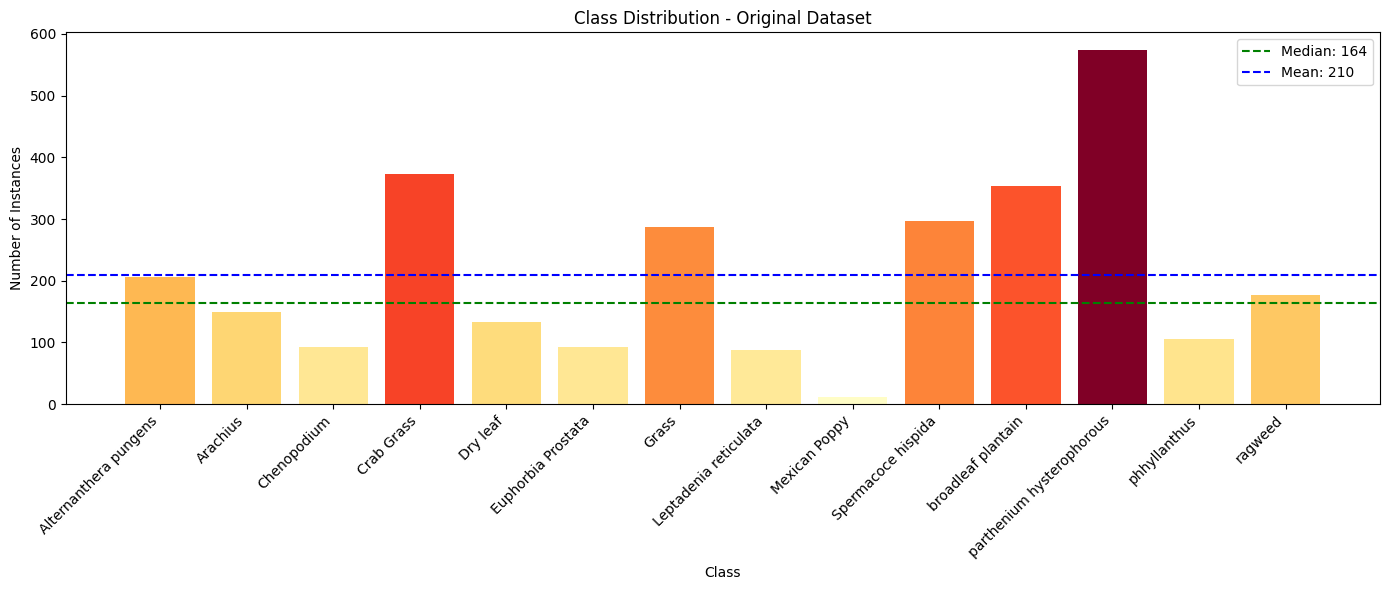

In [5]:
# Calculate imbalance metrics
total_instances = sum(class_counts.values())
print(f"Total instances: {total_instances}")
print(f"Mean instances per class: {total_instances/num_classes:.2f}")
print(f"Median instances per class: {np.median(list(class_counts.values())):.2f}")
print(f"Std deviation: {np.std(list(class_counts.values())):.2f}")
print(f"Max class: {max(class_counts.values())} (Class {max(class_counts, key=class_counts.get)})")
print(f"Min class: {min(class_counts.values())} (Class {min(class_counts, key=class_counts.get)})")
print(f"Imbalance ratio (max/min): {max(class_counts.values())/min(class_counts.values()):.2f}")

# Visualize imbalance
plt.figure(figsize=(14, 6))
classes = [class_names[i] for i in range(num_classes)]
counts = [class_counts.get(i, 0) for i in range(num_classes)]
colors = plt.cm.YlOrRd(np.array(counts) / max(counts))

plt.bar(range(len(classes)), counts, color=colors)
plt.xlabel('Class')
plt.ylabel('Number of Instances')
plt.title('Class Distribution - Original Dataset')
plt.xticks(range(len(classes)), classes, rotation=45, ha='right')
plt.axhline(y=np.median(counts), color='g', linestyle='--', label=f'Median: {np.median(counts):.0f}')
plt.axhline(y=np.mean(counts), color='b', linestyle='--', label=f'Mean: {np.mean(counts):.0f}')
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# Calculate detailed imbalance metrics
print("="*60)
print("DETAILED IMBALANCE ANALYSIS")
print("="*60)

# Calculate Gini coefficient (measure of inequality)
def gini_coefficient(counts):
    counts_sorted = np.sort(counts)
    n = len(counts_sorted)
    index = np.arange(1, n + 1)
    return (np.sum((2 * index - n - 1) * counts_sorted)) / (n * np.sum(counts_sorted))

counts_array = np.array([class_counts.get(i, 0) for i in range(num_classes)])
gini = gini_coefficient(counts_array)
print(f"Gini coefficient: {gini:.3f} (0=perfect balance, 1=extreme imbalance)")

# Identify severely underrepresented classes
severely_underrepresented = [i for i in range(num_classes) if class_counts.get(i, 0) < 50]
moderately_underrepresented = [i for i in range(num_classes) if 50 <= class_counts.get(i, 0) < 150]
well_represented = [i for i in range(num_classes) if class_counts.get(i, 0) >= 150]

print(f"\nSeverely underrepresented (<50 instances): {len(severely_underrepresented)} classes")
for cid in severely_underrepresented:
    print(f"  - {class_names[cid]}: {class_counts.get(cid, 0)} instances")

print(f"\nModerately underrepresented (50-150 instances): {len(moderately_underrepresented)} classes")
for cid in moderately_underrepresented:
    print(f"  - {class_names[cid]}: {class_counts.get(cid, 0)} instances")

print(f"\nWell represented (>150 instances): {len(well_represented)} classes")

# Recommended augmentation factors
print("\n" + "="*60)
print("RECOMMENDED AUGMENTATION STRATEGY")
print("="*60)

# Strategy: Balance to 300 instances for all classes
target_balanced = 200
print(f"Target: {target_balanced} instances per class")

for class_id in range(num_classes):
    current = class_counts.get(class_id, 0)
    if current < target_balanced:
        needed = target_balanced - current
        factor = needed / current if current > 0 else needed
        print(f"\nClass {class_id} - {class_names[class_id]}:")
        print(f"  Current: {current} → Target: {target_balanced} (+{needed})")
        print(f"  Augmentation factor: {factor:.1f}x")
        
        # Special handling for extremely small classes
        if current < 20:
            print(f"  ⚠️  EXTREME CASE: Only {current} instances available")
            print(f"  Recommendation: Use aggressive augmentation with multiple techniques")
            print(f"  Suggested augmentations per image: {min(20, int(factor) + 5)}")

DETAILED IMBALANCE ANALYSIS
Gini coefficient: 0.375 (0=perfect balance, 1=extreme imbalance)

Severely underrepresented (<50 instances): 1 classes
  - Mexican Poppy: 11 instances

Moderately underrepresented (50-150 instances): 5 classes
  - Chenopodium: 92 instances
  - Dry leaf: 133 instances
  - Euphorbia Prostata: 92 instances
  - Leptadenia reticulata: 87 instances
  - phhyllanthus: 105 instances

Well represented (>150 instances): 8 classes

RECOMMENDED AUGMENTATION STRATEGY
Target: 200 instances per class

Class 1 - Arachius:
  Current: 150 → Target: 200 (+50)
  Augmentation factor: 0.3x

Class 2 - Chenopodium:
  Current: 92 → Target: 200 (+108)
  Augmentation factor: 1.2x

Class 4 - Dry leaf:
  Current: 133 → Target: 200 (+67)
  Augmentation factor: 0.5x

Class 5 - Euphorbia Prostata:
  Current: 92 → Target: 200 (+108)
  Augmentation factor: 1.2x

Class 7 - Leptadenia reticulata:
  Current: 87 → Target: 200 (+113)
  Augmentation factor: 1.3x

Class 8 - Mexican Poppy:
  Current:

In [10]:
import os
import cv2
import numpy as np
import random
import shutil
import yaml
from collections import Counter, defaultdict
from tqdm import tqdm
import matplotlib.pyplot as plt
import albumentations as A
from albumentations import Compose
import warnings
warnings.filterwarnings('ignore')

# Define paths
DATASET_PATH = '/kaggle/input/datasets/matamdurgesh/only-weeds-dataset'
TRAIN_PATH = os.path.join(DATASET_PATH, 'train')
IMAGES_PATH = os.path.join(TRAIN_PATH, 'images')
LABELS_PATH = os.path.join(TRAIN_PATH, 'labels')

# Create working directory for augmented dataset (writable location)
WORK_DIR = '/kaggle/working/balanced_weed_dataset'
AUGMENTED_TRAIN_PATH = os.path.join(WORK_DIR, 'train')
AUGMENTED_IMAGES_PATH = os.path.join(AUGMENTED_TRAIN_PATH, 'images')
AUGMENTED_LABELS_PATH = os.path.join(AUGMENTED_TRAIN_PATH, 'labels')

# Create directories
os.makedirs(AUGMENTED_IMAGES_PATH, exist_ok=True)
os.makedirs(AUGMENTED_LABELS_PATH, exist_ok=True)

print(f"Working directory created: {WORK_DIR}")
print(f"Augmented images will be saved to: {AUGMENTED_IMAGES_PATH}")
print(f"Augmented labels will be saved to: {AUGMENTED_LABELS_PATH}")

# Define target instances per class based on your analysis
TARGET_INSTANCES = 200

# Define augmentation strategy for each class based on current counts
class_current_counts = {
    0: 206,   # Alternanthera pungens
    1: 150,   # Arachius
    2: 92,    # Chenopodium
    3: 373,   # Crab Grass
    4: 133,   # Dry leaf
    5: 92,    # Euphorbia Prostata
    6: 287,   # Grass
    7: 87,    # Leptadenia reticulata
    8: 11,    # Mexican Poppy
    9: 297,   # Spermacoce hispida
    10: 353,  # broadleaf plantain
    11: 574,  # parthenium hysterophorous
    12: 105,  # phhyllanthus
    13: 177   # ragweed
}

# Classes that need augmentation (those below target)
classes_to_augment = {
    class_id: current 
    for class_id, current in class_current_counts.items() 
    if current < TARGET_INSTANCES
}

print("\n" + "="*60)
print("AUGMENTATION PLAN")
print("="*60)
print(f"Target instances per class: {TARGET_INSTANCES}")
print(f"Classes requiring augmentation: {len(classes_to_augment)}")
print()

augmentation_config = {}

for class_id, current in sorted(classes_to_augment.items()):
    needed = TARGET_INSTANCES - current
    factor = needed / current if current > 0 else needed
    
    # Determine severity level and augmentations per image
    if current < 20:
        severity = "EXTREME"
        augs_per_image = 20
    elif current < 50:
        severity = "HIGH"
        augs_per_image = 12
    elif current < 100:
        severity = "MEDIUM"
        augs_per_image = 8
    else:
        severity = "LOW"
        augs_per_image = 4
    
    # Calculate how many images we need to process
    # First, find how many images contain this class
    # We'll calculate this later, but for now store the plan
    augmentation_config[class_id] = {
        'current': current,
        'needed': needed,
        'factor': factor,
        'severity': severity,
        'augs_per_image': augs_per_image
    }
    
    print(f"Class {class_id}:")
    print(f"  Current: {current} → Need: +{needed} (factor: {factor:.1f}x)")
    print(f"  Severity: {severity}")
    print(f"  Suggested augmentations per source image: {augs_per_image}")
    print()

# Copy original files to working directory
print("\n" + "="*60)
print("COPYING ORIGINAL FILES TO WORKING DIRECTORY")
print("="*60)

original_images = [f for f in os.listdir(IMAGES_PATH) if f.endswith(('.jpg', '.png', '.jpeg'))]

print(f"Copying {len(original_images)} original images...")
for img_file in tqdm(original_images):
    # Copy image
    src_img = os.path.join(IMAGES_PATH, img_file)
    dst_img = os.path.join(AUGMENTED_IMAGES_PATH, img_file)
    shutil.copy2(src_img, dst_img)
    
    # Copy label
    label_file = img_file.replace('.jpg', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt')
    src_label = os.path.join(LABELS_PATH, label_file)
    dst_label = os.path.join(AUGMENTED_LABELS_PATH, label_file)
    if os.path.exists(src_label):
        shutil.copy2(src_label, dst_label)

print(f"✓ Copied {len(original_images)} original images and their labels to working directory")

# Create mapping of images to class labels
print("\nCreating image-class mapping...")
image_to_classes = defaultdict(list)

for img_file in tqdm(original_images):
    label_file = img_file.replace('.jpg', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt')
    label_path = os.path.join(LABELS_PATH, label_file)
    
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f:
                class_id = int(line.strip().split()[0])
                image_to_classes[img_file].append(class_id)

print(f"✓ Created mapping for {len(image_to_classes)} images")

# Create reverse mapping: class to list of images
class_to_images = defaultdict(list)
for img_file, classes in image_to_classes.items():
    for class_id in classes:
        class_to_images[class_id].append(img_file)

print(f"✓ Created reverse mapping for {len(class_to_images)} classes")

# Display availability of images for each class needing augmentation
print("\n" + "="*60)
print("IMAGE AVAILABILITY FOR AUGMENTATION")
print("="*60)

for class_id, config in augmentation_config.items():
    num_images = len(class_to_images.get(class_id, []))
    config['num_available_images'] = num_images
    
    # Calculate total possible augmentations and required images to process
    if num_images > 0:
        total_possible = num_images * config['augs_per_image']
        images_needed = max(1, int(np.ceil(config['needed'] / config['augs_per_image'])))
        config['images_to_process'] = min(num_images, images_needed)
        
        print(f"Class {class_id}: {config['num_available_images']} images available")
        print(f"  → Need {config['needed']} augmentations")
        print(f"  → Each image will get {config['augs_per_image']} augmentations")
        print(f"  → Will process {config['images_to_process']} images")
        print(f"  → Total possible: {total_possible} (target: {config['needed']})")
    else:
        print(f"⚠️  WARNING: No images found for Class {class_id}!")
        config['images_to_process'] = 0
    
    print()

print("\n✓ Setup complete! Ready for augmentation.")

Working directory created: /kaggle/working/balanced_weed_dataset
Augmented images will be saved to: /kaggle/working/balanced_weed_dataset/train/images
Augmented labels will be saved to: /kaggle/working/balanced_weed_dataset/train/labels

AUGMENTATION PLAN
Target instances per class: 200
Classes requiring augmentation: 8

Class 1:
  Current: 150 → Need: +50 (factor: 0.3x)
  Severity: LOW
  Suggested augmentations per source image: 4

Class 2:
  Current: 92 → Need: +108 (factor: 1.2x)
  Severity: MEDIUM
  Suggested augmentations per source image: 8

Class 4:
  Current: 133 → Need: +67 (factor: 0.5x)
  Severity: LOW
  Suggested augmentations per source image: 4

Class 5:
  Current: 92 → Need: +108 (factor: 1.2x)
  Severity: MEDIUM
  Suggested augmentations per source image: 8

Class 7:
  Current: 87 → Need: +113 (factor: 1.3x)
  Severity: MEDIUM
  Suggested augmentations per source image: 8

Class 8:
  Current: 11 → Need: +189 (factor: 17.2x)
  Severity: EXTREME
  Suggested augmentations 

100%|██████████| 1090/1090 [01:03<00:00, 17.16it/s]


✓ Copied 1090 original images and their labels to working directory

Creating image-class mapping...


100%|██████████| 1090/1090 [00:01<00:00, 718.22it/s]

✓ Created mapping for 1090 images
✓ Created reverse mapping for 14 classes

IMAGE AVAILABILITY FOR AUGMENTATION
Class 1: 127 images available
  → Need 50 augmentations
  → Each image will get 4 augmentations
  → Will process 13 images
  → Total possible: 508 (target: 50)

Class 2: 90 images available
  → Need 108 augmentations
  → Each image will get 8 augmentations
  → Will process 14 images
  → Total possible: 720 (target: 108)

Class 4: 129 images available
  → Need 67 augmentations
  → Each image will get 4 augmentations
  → Will process 17 images
  → Total possible: 516 (target: 67)

Class 5: 81 images available
  → Need 108 augmentations
  → Each image will get 8 augmentations
  → Will process 14 images
  → Total possible: 648 (target: 108)

Class 7: 85 images available
  → Need 113 augmentations
  → Each image will get 8 augmentations
  → Will process 15 images
  → Total possible: 680 (target: 113)

Class 8: 6 images available
  → Need 189 augmentations
  → Each image will get 2

In [11]:
import albumentations as A
from albumentations import Compose

print("="*60)
print("DEFINING AUGMENTATION PIPELINES")
print("="*60)

# Preprocessing pipeline (applied to all images)
def get_preprocessing_pipeline():
    return Compose([
        A.Resize(640, 640),
        A.RandomBrightnessContrast(brightness_limit=0.0, contrast_limit=0.2, p=1.0),
    ])

# LOW severity augmentation (for classes with 100+ instances)
def get_low_severity_pipeline():
    return Compose([
        A.HorizontalFlip(p=0.5),
        A.HueSaturationValue(
            hue_shift_limit=10,
            sat_shift_limit=20,
            val_shift_limit=10,
            p=0.7
        ),
        A.RandomBrightnessContrast(
            brightness_limit=0.15,
            contrast_limit=0.15,
            p=0.7
        ),
    ])

# MEDIUM severity augmentation (for classes with 50-100 instances)
def get_medium_severity_pipeline():
    return Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.3),
        A.RandomRotate90(p=0.3),
        A.HueSaturationValue(
            hue_shift_limit=20,
            sat_shift_limit=30,
            val_shift_limit=20,
            p=0.8
        ),
        A.RandomBrightnessContrast(
            brightness_limit=0.22,
            contrast_limit=0.22,
            p=0.8
        ),
        A.GaussNoise(var_limit=(10.0, 40.0), p=0.3),
        A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=20, p=0.5),
    ])

# EXTREME severity augmentation (for Mexican Poppy - Class 8 with only 6 images)
def get_extreme_severity_pipeline():
    return Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.Transpose(p=0.3),
        A.ShiftScaleRotate(shift_limit=0.2, scale_limit=0.2, rotate_limit=45, p=0.8),
        A.HueSaturationValue(
            hue_shift_limit=30,
            sat_shift_limit=50,
            val_shift_limit=30,
            p=0.9
        ),
        A.RandomBrightnessContrast(
            brightness_limit=0.3,
            contrast_limit=0.3,
            p=0.9
        ),
        A.GaussNoise(var_limit=(10.0, 70.0), p=0.5),
        A.RandomGamma(gamma_limit=(70, 130), p=0.5),
        A.CLAHE(clip_limit=3.0, tile_grid_size=(8, 8), p=0.5),
        A.CoarseDropout(max_holes=8, max_height=64, max_width=64, p=0.4),
        A.ElasticTransform(alpha=1, sigma=50, alpha_affine=50, p=0.3),
        A.GridDistortion(num_steps=5, distort_limit=0.3, p=0.3),
    ])

# Motion blur function
def apply_motion_blur(image, length=10, angle=0):
    """Apply motion blur with specific angle"""
    kernel = np.zeros((length, length), dtype=np.float32)
    kernel[int((length-1)/2), :] = np.ones(length)
    kernel = kernel / length
    
    M = cv2.getRotationMatrix2D((length/2, length/2), angle, 1)
    kernel = cv2.warpAffine(kernel, M, (length, length))
    
    blurred = cv2.filter2D(image, -1, kernel)
    return blurred

def apply_varied_motion_blur(image):
    """Apply motion blur with random parameters"""
    length = random.randint(8, 15)
    angle = random.choice([0, 45, 90, 135, 180, 225, 270, 315])
    return apply_motion_blur(image, length, angle)

print("✓ Preprocessing pipeline defined")
print("✓ LOW severity pipeline defined")
print("✓ MEDIUM severity pipeline defined")
print("✓ EXTREME severity pipeline defined")
print("✓ Motion blur functions defined")

# Adjust strategy for Class 8 (Mexican Poppy) due to limited images
print("\n" + "="*60)
print("ADJUSTED STRATEGY FOR CLASS 8 (MEXICAN POPPY)")
print("="*60)

# Class 8 only has 6 images, we need 189 augmentations
# With 6 images × 20 augmentations = 120 max, which is less than 189
# Let's increase augmentations per image to 32 to reach closer to target
class_8_images = len(class_to_images[8])
class_8_needed = augmentation_config[8]['needed']
augs_per_image_adjusted = max(20, int(np.ceil(class_8_needed / class_8_images)))

print(f"Original plan: {class_8_images} images × 20 augmentations = 120 max")
print(f"Need: {class_8_needed} augmentations")
print(f"Adjusted: {class_8_images} images × {augs_per_image_adjusted} augmentations = {class_8_images * augs_per_image_adjusted} max")
print(f"Will generate as many as possible (up to {min(class_8_needed, class_8_images * augs_per_image_adjusted)})")

# Update configuration for Class 8
augmentation_config[8]['augs_per_image'] = augs_per_image_adjusted
augmentation_config[8]['images_to_process'] = class_8_images

print(f"\n✓ Updated Class 8 to generate {augs_per_image_adjusted} augmentations per image")
print(f"✓ Will process all {class_8_images} available images")

# Display final augmentation plan
print("\n" + "="*60)
print("FINAL AUGMENTATION PLAN")
print("="*60)
for class_id, config in augmentation_config.items():
    print(f"Class {class_id}:")
    print(f"  Severity: {config['severity']}")
    print(f"  Augmentations per image: {config['augs_per_image']}")
    print(f"  Images to process: {config['images_to_process']}")
    print(f"  Target: {config['needed']}")
    print(f"  Est. generated: {config['images_to_process'] * config['augs_per_image']}")
    print()

DEFINING AUGMENTATION PIPELINES
✓ Preprocessing pipeline defined
✓ LOW severity pipeline defined
✓ MEDIUM severity pipeline defined
✓ EXTREME severity pipeline defined
✓ Motion blur functions defined

ADJUSTED STRATEGY FOR CLASS 8 (MEXICAN POPPY)
Original plan: 6 images × 20 augmentations = 120 max
Need: 189 augmentations
Adjusted: 6 images × 32 augmentations = 192 max
Will generate as many as possible (up to 189)

✓ Updated Class 8 to generate 32 augmentations per image
✓ Will process all 6 available images

FINAL AUGMENTATION PLAN
Class 1:
  Severity: LOW
  Augmentations per image: 4
  Images to process: 13
  Target: 50
  Est. generated: 52

Class 2:
  Severity: MEDIUM
  Augmentations per image: 8
  Images to process: 14
  Target: 108
  Est. generated: 112

Class 4:
  Severity: LOW
  Augmentations per image: 4
  Images to process: 17
  Target: 67
  Est. generated: 68

Class 5:
  Severity: MEDIUM
  Augmentations per image: 8
  Images to process: 14
  Target: 108
  Est. generated: 112


In [12]:
import random
from tqdm import tqdm
import cv2
import numpy as np

print("="*60)
print("STARTING AUGMENTATION GENERATION")
print("="*60)

# Track augmentations performed
augmentations_done = {class_id: 0 for class_id in augmentation_config.keys()}
augmented_count_total = 0

# Store which images we've processed for each class
processed_images = {class_id: [] for class_id in augmentation_config.keys()}

# For each class that needs augmentation
for class_id, config in augmentation_config.items():
    print(f"\n{'='*60}")
    print(f"Processing Class {class_id}:")
    print(f"  Severity: {config['severity']}")
    print(f"  Need: {config['needed']} augmentations")
    print(f"  Augmentations per image: {config['augs_per_image']}")
    print(f"  Images to process: {config['images_to_process']}")
    print(f"{'='*60}")
    
    # Get images that contain this class
    available_images = class_to_images[class_id]
    
    # Select images to process (random selection)
    images_to_process = random.sample(
        available_images, 
        min(config['images_to_process'], len(available_images))
    )
    
    # Select augmentation pipeline based on severity
    if config['severity'] == 'EXTREME':
        aug_pipeline = get_extreme_severity_pipeline()
        use_varied_blur = True
    elif config['severity'] == 'MEDIUM':
        aug_pipeline = get_medium_severity_pipeline()
        use_varied_blur = True
    else:  # LOW
        aug_pipeline = get_low_severity_pipeline()
        use_varied_blur = False
    
    # Process each image
    for img_file in tqdm(images_to_process, desc=f"Augmenting Class {class_id}"):
        if augmentations_done[class_id] >= config['needed']:
            break
        
        # Load image
        img_path = os.path.join(IMAGES_PATH, img_file)
        img = cv2.imread(img_path)
        if img is None:
            print(f"Warning: Could not load {img_file}")
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Load labels
        label_file = img_file.replace('.jpg', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt')
        label_path = os.path.join(LABELS_PATH, label_file)
        
        with open(label_path, 'r') as f:
            original_labels = [line.strip() for line in f.readlines()]
        
        # Apply preprocessing
        preprocessed = get_preprocessing_pipeline()(image=img)
        img_preprocessed = preprocessed['image']
        
        # Generate multiple augmentations for this image
        for aug_idx in range(config['augs_per_image']):
            if augmentations_done[class_id] >= config['needed']:
                break
            
            try:
                # Apply augmentation pipeline
                augmented = aug_pipeline(image=img_preprocessed)
                img_augmented = augmented['image']
                
                # Apply motion blur (varied for extreme cases)
                if use_varied_blur:
                    img_augmented = apply_varied_motion_blur(img_augmented)
                else:
                    img_augmented = apply_motion_blur(img_augmented, length=8, angle=0)
                
                # Create filename for augmented image
                base_name = os.path.splitext(img_file)[0]
                aug_img_name = f"{base_name}_class{class_id}_aug{aug_idx}.jpg"
                aug_label_name = f"{base_name}_class{class_id}_aug{aug_idx}.txt"
                
                # Save augmented image
                aug_img_path = os.path.join(AUGMENTED_IMAGES_PATH, aug_img_name)
                img_augmented_bgr = cv2.cvtColor(img_augmented, cv2.COLOR_RGB2BGR)
                cv2.imwrite(aug_img_path, img_augmented_bgr)
                
                # Save labels (same as original)
                aug_label_path = os.path.join(AUGMENTED_LABELS_PATH, aug_label_name)
                with open(aug_label_path, 'w') as f:
                    f.write('\n'.join(original_labels))
                
                augmentations_done[class_id] += 1
                augmented_count_total += 1
                
            except Exception as e:
                print(f"Error augmenting {img_file}: {e}")
                continue
    
    # Report progress for this class
    print(f"\n✓ Class {class_id}: Generated {augmentations_done[class_id]}/{config['needed']} augmentations")
    print(f"  {'✓ Target reached!' if augmentations_done[class_id] >= config['needed'] else '⚠️ Short by ' + str(config['needed'] - augmentations_done[class_id])}")

print("\n" + "="*60)
print("AUGMENTATION GENERATION COMPLETE!")
print("="*60)
print(f"Total augmentations generated: {augmented_count_total}")
print(f"Total images in augmented dataset: {len(os.listdir(AUGMENTED_IMAGES_PATH))}")

STARTING AUGMENTATION GENERATION

Processing Class 1:
  Severity: LOW
  Need: 50 augmentations
  Augmentations per image: 4
  Images to process: 13


Augmenting Class 1: 100%|██████████| 13/13 [00:02<00:00,  5.18it/s]



✓ Class 1: Generated 50/50 augmentations
  ✓ Target reached!

Processing Class 2:
  Severity: MEDIUM
  Need: 108 augmentations
  Augmentations per image: 8
  Images to process: 14


Augmenting Class 2: 100%|██████████| 14/14 [00:05<00:00,  2.50it/s]



✓ Class 2: Generated 108/108 augmentations
  ✓ Target reached!

Processing Class 4:
  Severity: LOW
  Need: 67 augmentations
  Augmentations per image: 4
  Images to process: 17


Augmenting Class 4: 100%|██████████| 17/17 [00:03<00:00,  5.25it/s]


... (7 outputs left out)

Augmenting Class 12: 100%|██████████| 24/24 [00:04<00:00,  5.38it/s]



✓ Class 12: Generated 95/95 augmentations
  ✓ Target reached!

Processing Class 13:
  Severity: LOW
  Need: 23 augmentations
  Augmentations per image: 4
  Images to process: 6


Augmenting Class 13: 100%|██████████| 6/6 [00:01<00:00,  5.72it/s]


✓ Class 13: Generated 23/23 augmentations
  ✓ Target reached!

AUGMENTATION GENERATION COMPLETE!
Total augmentations generated: 753
Total images in augmented dataset: 1795


VERIFYING BALANCED DATASET

FINAL CLASS DISTRIBUTION:
--------------------------------------------------------------------------------
Class ID   Class Name                          Original     Final        Change    
--------------------------------------------------------------------------------
0          Alternanthera pungens               206          213          +7 ✓
1          Arachius                            150          252          +102 ✓
2          Chenopodium                         92           382          +290 ✓
3          Crab Grass                          373          377          +4 ✓
4          Dry leaf                            133          298          +165 ✓
5          Euphorbia Prostata                  92           220          +128 ✓
6          Grass                               287          371          +84 ✓
7          Leptadenia reticulata               87           262          +175 ✓
8          Mexican Poppy                       11           198  

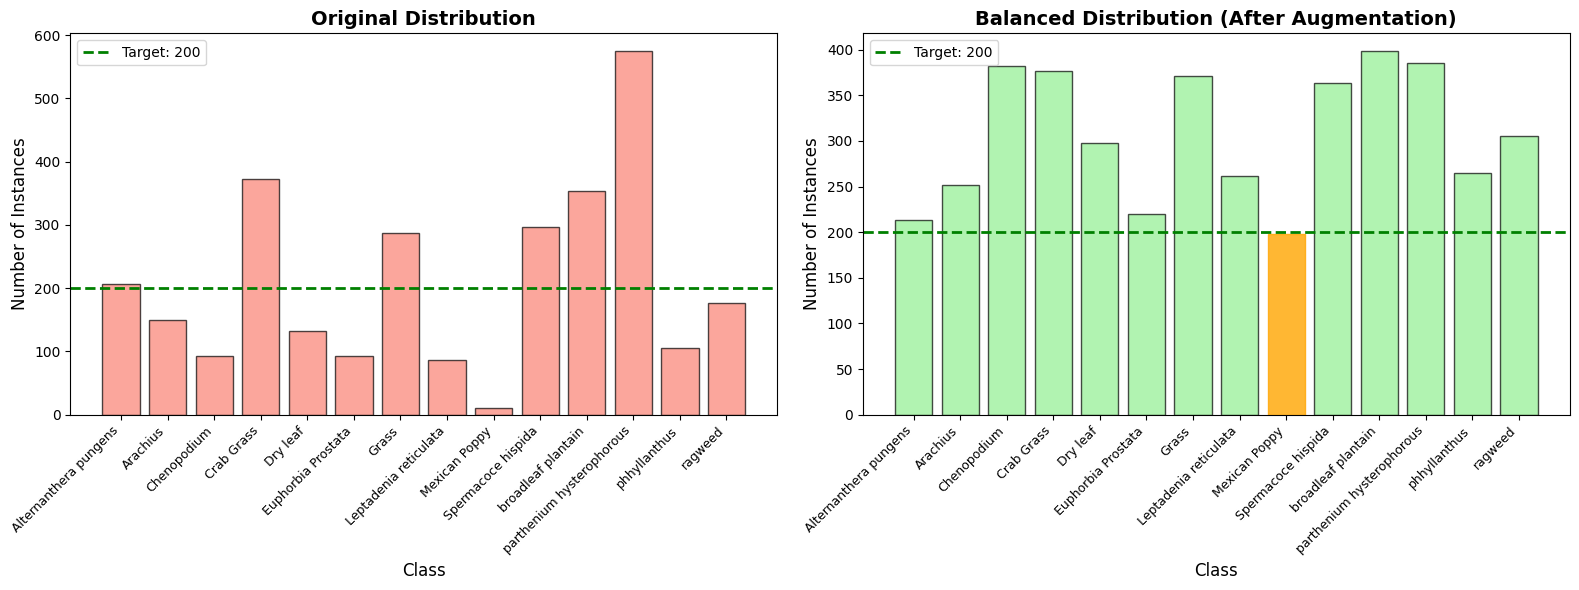


✓ Distribution visualization saved to: /kaggle/working/balanced_dataset_distribution.png


In [13]:
import matplotlib.pyplot as plt
import numpy as np
import yaml
from collections import Counter

print("="*60)
print("VERIFYING BALANCED DATASET")
print("="*60)

# Function to count class instances in the augmented dataset
def count_class_occurrences_final(labels_path):
    class_counts = Counter()
    total_labels = 0
    
    for label_file in os.listdir(labels_path):
        if label_file.endswith('.txt'):
            with open(os.path.join(labels_path, label_file), 'r') as f:
                lines = f.readlines()
                for line in lines:
                    class_id = int(line.strip().split()[0])
                    class_counts[class_id] += 1
                    total_labels += 1
    
    return class_counts, total_labels

# Count instances in final dataset
final_counts, total_labels = count_class_occurrences_final(AUGMENTED_LABELS_PATH)

# Load class names
with open(os.path.join(DATASET_PATH, 'data.yaml'), 'r') as f:
    data_yaml = yaml.safe_load(f)
class_names = data_yaml['names']

print("\nFINAL CLASS DISTRIBUTION:")
print("-"*80)
print(f"{'Class ID':<10} {'Class Name':<35} {'Original':<12} {'Final':<12} {'Change':<10}")
print("-"*80)

for class_id in range(len(class_names)):
    original = class_current_counts.get(class_id, 0)
    final = final_counts.get(class_id, 0)
    change = final - original
    status = "✓" if final >= 200 else "⚠️"
    print(f"{class_id:<10} {class_names[class_id][:35]:<35} {original:<12} {final:<12} {change:+d} {status}")

print("-"*80)
print(f"Total instances: {total_labels} (Original: 2937, Added: {total_labels - 2937})")

# Calculate metrics
original_counts_list = [class_current_counts.get(i, 0) for i in range(len(class_names))]
final_counts_list = [final_counts.get(i, 0) for i in range(len(class_names))]

original_min = min(original_counts_list)
original_max = max(original_counts_list)
final_min = min(final_counts_list)
final_max = max(final_counts_list)

print("\n" + "="*60)
print("IMBALANCE METRICS COMPARISON")
print("="*60)
print(f"Min instances: {original_min} → {final_min}")
print(f"Max instances: {original_max} → {final_max}")
print(f"Max/Min ratio: {original_max/original_min:.1f} → {final_max/final_min:.1f}")

# Calculate improvement
if original_min > 0:
    improvement = (1 - (final_max/final_min) / (original_max/original_min)) * 100
    print(f"Imbalance reduction: {improvement:.1f}%")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Original distribution
axes[0].bar(range(len(class_names)), original_counts_list, color='salmon', alpha=0.7, edgecolor='black')
axes[0].set_xlabel('Class', fontsize=12)
axes[0].set_ylabel('Number of Instances', fontsize=12)
axes[0].set_title('Original Distribution', fontsize=14, fontweight='bold')
axes[0].set_xticks(range(len(class_names)))
axes[0].set_xticklabels(class_names, rotation=45, ha='right', fontsize=9)
axes[0].axhline(y=200, color='green', linestyle='--', linewidth=2, label='Target: 200')
axes[0].legend()

# Final distribution
bars = axes[1].bar(range(len(class_names)), final_counts_list, color='lightgreen', alpha=0.7, edgecolor='black')
axes[1].set_xlabel('Class', fontsize=12)
axes[1].set_ylabel('Number of Instances', fontsize=12)
axes[1].set_title('Balanced Distribution (After Augmentation)', fontsize=14, fontweight='bold')
axes[1].set_xticks(range(len(class_names)))
axes[1].set_xticklabels(class_names, rotation=45, ha='right', fontsize=9)
axes[1].axhline(y=200, color='green', linestyle='--', linewidth=2, label='Target: 200')
axes[1].legend()

# Color bars that are below target
for i, (bar, count) in enumerate(zip(bars, final_counts_list)):
    if count < 200:
        bar.set_color('orange')
        bar.set_alpha(0.8)

plt.tight_layout()
plt.savefig('/kaggle/working/balanced_dataset_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Distribution visualization saved to: /kaggle/working/balanced_dataset_distribution.png")

In [14]:
# Create updated data.yaml for the balanced dataset
balanced_yaml = {
    'path': WORK_DIR,
    'train': os.path.join(AUGMENTED_TRAIN_PATH, 'images'),
    'val': data_yaml.get('val', ''),  # Keep original validation path if exists
    'nc': len(class_names),
    'names': class_names
}

# Save updated yaml
balanced_yaml_path = os.path.join(WORK_DIR, 'data_balanced.yaml')
with open(balanced_yaml_path, 'w') as f:
    yaml.dump(balanced_yaml, f, default_flow_style=False)

print("="*60)
print("BALANCED DATASET SUMMARY")
print("="*60)
print(f"Dataset location: {WORK_DIR}")
print(f"Training images: {len(os.listdir(AUGMENTED_IMAGES_PATH))}")
print(f"Training labels: {len(os.listdir(AUGMENTED_LABELS_PATH))}")
print(f"Number of classes: {len(class_names)}")
print(f"Target instances per class: 200")
print(f"Data config file: {balanced_yaml_path}")

print("\nUpdated data.yaml content:")
print("-"*60)
print(yaml.dump(balanced_yaml, default_flow_style=False))

# Verify all classes reached target
classes_below_target = [class_names[i] for i in range(len(class_names)) 
                        if final_counts.get(i, 0) < 200]

if classes_below_target:
    print(f"\n⚠️ Warning: These classes are below target: {classes_below_target}")
else:
    print("\n✓ All classes have reached the target of 200 instances!")

BALANCED DATASET SUMMARY
Dataset location: /kaggle/working/balanced_weed_dataset
Training images: 1795
Training labels: 1795
Number of classes: 14
Target instances per class: 200
Data config file: /kaggle/working/balanced_weed_dataset/data_balanced.yaml

Updated data.yaml content:
------------------------------------------------------------
names:
- Alternanthera pungens
- Arachius
- Chenopodium
- Crab Grass
- Dry leaf
- Euphorbia Prostata
- Grass
- Leptadenia reticulata
- Mexican Poppy
- Spermacoce hispida
- broadleaf plantain
- parthenium hysterophorous
- phhyllanthus
- ragweed
nc: 14
path: /kaggle/working/balanced_weed_dataset
train: /kaggle/working/balanced_weed_dataset/train/images
val: ../valid/images


⚠️ Warning: These classes are below target: ['Mexican Poppy']


SAMPLE AUGMENTED IMAGES
Total original images: 1090
Total augmented images: 705
Total images in balanced dataset: 1795
No augmented versions found for the selected image

MEXICAN POPPY (Class 8) - AUGMENTATION EXAMPLES


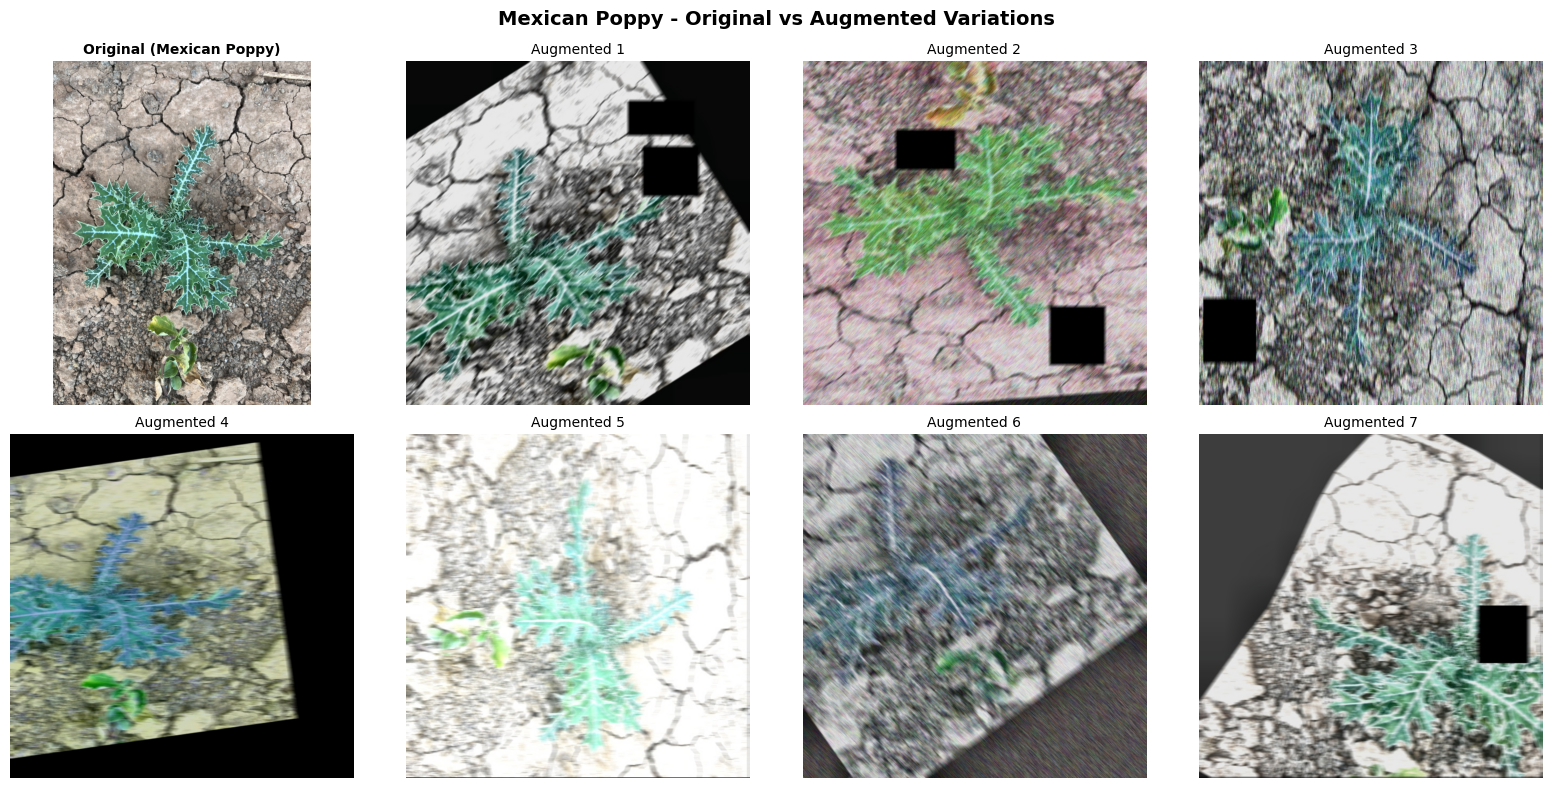

✓ Mexican Poppy augmentations saved to: /kaggle/working/mexican_poppy_augmentations.png

DATASET BALANCING COMPLETE!
Final balanced dataset location: /kaggle/working/balanced_weed_dataset
Data config file: /kaggle/working/balanced_weed_dataset/data_balanced.yaml

You can now use this balanced dataset for training your model.


In [15]:
import random
import matplotlib.pyplot as plt

print("="*60)
print("SAMPLE AUGMENTED IMAGES")
print("="*60)

# Get all augmented files (excluding original files)
all_files = os.listdir(AUGMENTED_IMAGES_PATH)
original_files = [f for f in os.listdir(IMAGES_PATH) if f.endswith(('.jpg', '.png', '.jpeg'))]
augmented_files = [f for f in all_files if f not in original_files]

print(f"Total original images: {len(original_files)}")
print(f"Total augmented images: {len(augmented_files)}")
print(f"Total images in balanced dataset: {len(all_files)}")

# Select a random original image and its augmentations
if original_files:
    sample_original = random.choice(original_files)
    base_name = os.path.splitext(sample_original)[0]
    
    # Find its augmented versions
    related_augmented = [f for f in augmented_files if f.startswith(base_name)]
    
    if related_augmented:
        # Display original and up to 5 augmentations
        num_to_show = min(5, len(related_augmented))
        
        fig, axes = plt.subplots(1, num_to_show + 1, figsize=(15, 4))
        
        # Original image
        orig_img_path = os.path.join(AUGMENTED_IMAGES_PATH, sample_original)
        orig_img = cv2.imread(orig_img_path)
        orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
        axes[0].imshow(orig_img)
        axes[0].set_title(f'Original\n{os.path.splitext(sample_original)[0]}', fontsize=10)
        axes[0].axis('off')
        
        # Augmented versions
        for i, aug_file in enumerate(related_augmented[:num_to_show]):
            aug_img_path = os.path.join(AUGMENTED_IMAGES_PATH, aug_file)
            aug_img = cv2.imread(aug_img_path)
            aug_img = cv2.cvtColor(aug_img, cv2.COLOR_BGR2RGB)
            axes[i+1].imshow(aug_img)
            axes[i+1].set_title(f'Augmented {i+1}', fontsize=10)
            axes[i+1].axis('off')
        
        plt.suptitle('Original vs Augmented Images', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig('/kaggle/working/augmentation_samples.png', dpi=150, bbox_inches='tight')
        plt.show()
        
        print(f"\n✓ Augmentation samples saved to: /kaggle/working/augmentation_samples.png")
    else:
        print("No augmented versions found for the selected image")
else:
    print("No original images found")

# Show a specific class example (Mexican Poppy)
print("\n" + "="*60)
print("MEXICAN POPPY (Class 8) - AUGMENTATION EXAMPLES")
print("="*60)

# Find images containing Mexican Poppy
mexican_poppy_images = class_to_images.get(8, [])
if mexican_poppy_images:
    sample_mp = random.choice(mexican_poppy_images)
    base_name = os.path.splitext(sample_mp)[0]
    mp_augmented = [f for f in augmented_files if f.startswith(base_name) and 'class8' in f]
    
    if mp_augmented:
        fig, axes = plt.subplots(2, 4, figsize=(16, 8))
        axes = axes.flatten()
        
        # Original
        orig_img_path = os.path.join(AUGMENTED_IMAGES_PATH, sample_mp)
        orig_img = cv2.imread(orig_img_path)
        orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
        axes[0].imshow(orig_img)
        axes[0].set_title('Original (Mexican Poppy)', fontsize=10, fontweight='bold')
        axes[0].axis('off')
        
        # Show 7 augmented versions
        for i, aug_file in enumerate(mp_augmented[:7]):
            aug_img_path = os.path.join(AUGMENTED_IMAGES_PATH, aug_file)
            aug_img = cv2.imread(aug_img_path)
            aug_img = cv2.cvtColor(aug_img, cv2.COLOR_BGR2RGB)
            axes[i+1].imshow(aug_img)
            axes[i+1].set_title(f'Augmented {i+1}', fontsize=10)
            axes[i+1].axis('off')
        
        plt.suptitle('Mexican Poppy - Original vs Augmented Variations', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig('/kaggle/working/mexican_poppy_augmentations.png', dpi=150, bbox_inches='tight')
        plt.show()
        print("✓ Mexican Poppy augmentations saved to: /kaggle/working/mexican_poppy_augmentations.png")
    else:
        print("No augmented versions found for Mexican Poppy")
else:
    print("No Mexican Poppy images found")

print("\n" + "="*60)
print("DATASET BALANCING COMPLETE!")
print("="*60)
print(f"Final balanced dataset location: {WORK_DIR}")
print(f"Data config file: {balanced_yaml_path}")
print("\nYou can now use this balanced dataset for training your model.")

In [16]:
import zipfile
import os
from tqdm import tqdm

print("="*60)
print("CREATING ZIP FILE OF BALANCED DATASET")
print("="*60)

# Define paths
WORK_DIR = '/kaggle/working/balanced_weed_dataset'
ZIP_PATH = '/kaggle/working/balanced_weed_dataset.zip'

# Calculate total size before zipping
total_size = 0
for dirpath, dirnames, filenames in os.walk(WORK_DIR):
    for f in filenames:
        fp = os.path.join(dirpath, f)
        total_size += os.path.getsize(fp)

print(f"Dataset location: {WORK_DIR}")
print(f"Total size: {total_size / (1024*1024):.2f} MB")
print(f"Total files: {sum(len(files) for _, _, files in os.walk(WORK_DIR))}")

# Create zip file
print("\nCreating zip file...")
print("This may take a few minutes depending on dataset size.")

with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as zipf:
    # Walk through all files in the dataset
    for root, dirs, files in tqdm(os.walk(WORK_DIR), desc="Zipping files"):
        for file in files:
            file_path = os.path.join(root, file)
            # Create archive path relative to WORK_DIR
            arcname = os.path.relpath(file_path, os.path.dirname(WORK_DIR))
            zipf.write(file_path, arcname)

# Get zip file size
zip_size = os.path.getsize(ZIP_PATH)

print(f"\n✓ Zip file created successfully!")
print(f"  Location: {ZIP_PATH}")
print(f"  Size: {zip_size / (1024*1024):.2f} MB")
print(f"  Compression ratio: {(1 - zip_size/total_size)*100:.1f}%")

CREATING ZIP FILE OF BALANCED DATASET
Dataset location: /kaggle/working/balanced_weed_dataset
Total size: 4641.13 MB
Total files: 3591

Creating zip file...
This may take a few minutes depending on dataset size.


Zipping files: 4it [02:57, 44.46s/it]


✓ Zip file created successfully!
  Location: /kaggle/working/balanced_weed_dataset.zip
  Size: 4543.72 MB
  Compression ratio: 2.1%


In [17]:
from IPython.display import FileLink, display
import os

ZIP_PATH = '/kaggle/working/balanced_weed_dataset.zip'

if os.path.exists(ZIP_PATH):
    zip_size = os.path.getsize(ZIP_PATH) / (1024*1024)
    print("="*60)
    print("✅ ZIP FILE IS READY FOR DOWNLOAD!")
    print("="*60)
    print(f"File: balanced_weed_dataset.zip")
    print(f"Size: {zip_size:.2f} MB")
    print("\nClick the link below to download:")
    print("-"*60)
    
    display(FileLink(ZIP_PATH))
    
    print("\n" + "="*60)
    print("ALTERNATIVE DOWNLOAD METHOD:")
    print("="*60)
    print("1. Click on 'Output' tab in the right panel")
    print("2. Navigate to /kaggle/working/")
    print("3. Right-click on 'balanced_weed_dataset.zip'")
    print("4. Select 'Download'")
    
else:
    print("Zip file not found. Please wait for compression to complete.")
    print("Check back in a few minutes.")

✅ ZIP FILE IS READY FOR DOWNLOAD!
File: balanced_weed_dataset.zip
Size: 4543.72 MB

Click the link below to download:
------------------------------------------------------------


/kaggle/working/balanced_weed_dataset.zip


ALTERNATIVE DOWNLOAD METHOD:
1. Click on 'Output' tab in the right panel
2. Navigate to /kaggle/working/
3. Right-click on 'balanced_weed_dataset.zip'
4. Select 'Download'


In [19]:
import zipfile
import os

ZIP_PATH = '/kaggle/working/balanced_weed_dataset.zip'

if os.path.exists(ZIP_PATH):
    print("="*60)
    print("VERIFYING ZIP FILE CONTENTS")
    print("="*60)
    
    # Open zip and analyze contents
    with zipfile.ZipFile(ZIP_PATH, 'r') as zipf:
        file_list = zipf.namelist()
        
        # Filter image files
        all_images = [f for f in file_list if f.endswith(('.jpg', '.png', '.jpeg'))]
        
        # Separate original and augmented
        original_images = [f for f in all_images if 'aug' not in f.lower()]
        augmented_images = [f for f in all_images if 'aug' in f.lower()]
        
        print(f"\n📊 ZIP FILE CONTENTS:")
        print("-"*60)
        print(f"Total images: {len(all_images)}")
        print(f"  - Original images: {len(original_images)}")
        print(f"  - Augmented images: {len(augmented_images)}")
        
        # Show sample of original images
        print(f"\n📁 Sample Original Images (first 5):")
        for img in original_images[:5]:
            print(f"  • {img.split('/')[-1]}")
        
        # Show sample of augmented images
        print(f"\n🔧 Sample Augmented Images (first 5):")
        for img in augmented_images[:5]:
            print(f"  • {img.split('/')[-1]}")
        
        print(f"\n✅ The zip contains BOTH original and augmented images!")
        print(f"   Total: {len(original_images)} original + {len(augmented_images)} augmented = {len(all_images)} images")
        
else:
    print("Zip file not found yet")

VERIFYING ZIP FILE CONTENTS

📊 ZIP FILE CONTENTS:
------------------------------------------------------------
Total images: 1795
  - Original images: 1090
  - Augmented images: 705

📁 Sample Original Images (first 5):
  • IMG_20251228_172034_jpg.rf.8AT0dkTY7r7CItZHujlF.jpg
  • IMG_20251228_172124_jpg.rf.xLohGrXKjexIi31o0Tm5.jpg
  • Copy of IMG_20251228_171735_jpg.rf.9lCqkFvFPmUtV8NQJ6aj.jpg
  • Copy of IMG_20251217_165915_jpg.rf.OuCIUtAwfbGhnqumvbze.jpg
  • IMG_3872_jpg.rf.7Wli5k2CDWPbUWu6P5bN.jpg

🔧 Sample Augmented Images (first 5):
  • IMG_3825_jpg.rf.NyTFUA8uuKVSebXtPm6w_class8_aug1.jpg
  • Copy of IMG_20251229_173315_jpg.rf.xAGRdvcySKwA6pR7urci_class12_aug0.jpg
  • Copy of IMG_20251228_173753_jpg.rf.Dqaw42EmphZGUFhKHiPa_class5_aug3.jpg
  • IMG_20251102_174550_jpg.rf.68OclHABznX0LtetsyWm_class7_aug1.jpg
  • IMG_3838_jpg.rf.ioUnIVif1prUdtoaATtn_class5_aug1.jpg

✅ The zip contains BOTH original and augmented images!
   Total: 1090 original + 705 augmented = 1795 images


In [20]:
from google.colab import drive
import os
import shutil

# This is for Google Colab - if you're using Kaggle, we'll use a different approach
print("="*60)
print("OPTION 1: UPLOAD TO GOOGLE DRIVE")
print("="*60)

# Mount Google Drive (for Colab)
# drive.mount('/content/drive')

# For Kaggle, we'll use Kaggle Dataset API
print("\nSince the file is large, let's upload it as a Kaggle dataset instead.")

# Create dataset metadata
import json

metadata = {
    "title": "Balanced Weeds Dataset",
    "id": "your-username/balanced-weeds-dataset",
    "licenses": [{"name": "CC0-1.0"}]
}

# Save metadata
with open('/kaggle/working/dataset-metadata.json', 'w') as f:
    json.dump(metadata, f)

print("\nTo upload to Kaggle Datasets:")
print("1. Go to https://www.kaggle.com/datasets")
print("2. Click 'New Dataset'")
print("3. Upload the zip file from: /kaggle/working/balanced_weed_dataset.zip")
print("4. Fill in the details and publish")

OPTION 1: UPLOAD TO GOOGLE DRIVE

Since the file is large, let's upload it as a Kaggle dataset instead.

To upload to Kaggle Datasets:
1. Go to https://www.kaggle.com/datasets
2. Click 'New Dataset'
3. Upload the zip file from: /kaggle/working/balanced_weed_dataset.zip
4. Fill in the details and publish


In [21]:
import os

print("="*60)
print("CREATING SYMLINK TO INPUT DIRECTORY")
print("="*60)

ZIP_FILE = '/kaggle/working/balanced_weed_dataset.zip'
SYMLINK_PATH = '/kaggle/input/balanced_weed_dataset.zip'

if os.path.exists(ZIP_FILE):
    try:
        # Create symlink
        os.symlink(ZIP_FILE, SYMLINK_PATH)
        print(f"✓ Symlink created: {SYMLINK_PATH} -> {ZIP_FILE}")
        print("\nNow you can access the file at:")
        print(f"  /kaggle/input/balanced_weed_dataset.zip")
        
        # Verify
        if os.path.exists(SYMLINK_PATH):
            size = os.path.getsize(SYMLINK_PATH) / (1024*1024*1024)
            print(f"  Size: {size:.2f} GB")
        else:
            print("⚠️ Symlink created but not accessible?")
    except Exception as e:
        print(f"Cannot create symlink: {e}")
        print("\nInput directory is read-only, cannot write directly.")
        print("Symlink might not work in Kaggle environment.")
else:
    print("Zip file not found!")

CREATING SYMLINK TO INPUT DIRECTORY
Cannot create symlink: [Errno 30] Read-only file system: '/kaggle/working/balanced_weed_dataset.zip' -> '/kaggle/input/balanced_weed_dataset.zip'

Input directory is read-only, cannot write directly.
Symlink might not work in Kaggle environment.


In [22]:
import shutil
import os

print("="*60)
print("TRYING TO COPY TO INPUT DIRECTORY")
print("="*60)

ZIP_FILE = '/kaggle/working/balanced_weed_dataset.zip'
INPUT_COPY = '/kaggle/input/balanced_weed_dataset.zip'

if os.path.exists(ZIP_FILE):
    try:
        print(f"Attempting to copy {ZIP_FILE} to {INPUT_COPY}...")
        shutil.copy2(ZIP_FILE, INPUT_COPY)
        print("✓ File copied successfully!")
        
        # Verify
        if os.path.exists(INPUT_COPY):
            size = os.path.getsize(INPUT_COPY) / (1024*1024*1024)
            print(f"  Size: {size:.2f} GB")
    except Exception as e:
        print(f"Cannot copy: {e}")
        print("\nThe input directory is read-only in Kaggle.")
        print("Files can only be read from input, not written.")
else:
    print("Zip file not found!")

TRYING TO COPY TO INPUT DIRECTORY
Attempting to copy /kaggle/working/balanced_weed_dataset.zip to /kaggle/input/balanced_weed_dataset.zip...
Cannot copy: [Errno 30] Read-only file system: '/kaggle/input/balanced_weed_dataset.zip'

The input directory is read-only in Kaggle.
Files can only be read from input, not written.


In [23]:
print("="*60)
print("CREATE KAGGLE DATASET FROM THE ZIP")
print("="*60)

import json
import os
import shutil

# Create dataset structure
DATASET_DIR = '/kaggle/working/weed_dataset_for_kaggle'
os.makedirs(DATASET_DIR, exist_ok=True)

# Copy the zip to dataset directory
ZIP_FILE = '/kaggle/working/balanced_weed_dataset.zip'
if os.path.exists(ZIP_FILE):
    shutil.copy2(ZIP_FILE, os.path.join(DATASET_DIR, 'balanced_weed_dataset.zip'))
    print(f"✓ Copied zip to: {DATASET_DIR}")

# Create dataset metadata
metadata = {
    "title": "Balanced Weeds Dataset",
    "id": "yourusername/balanced-weeds-dataset",
    "licenses": [{"name": "CC0-1.0"}],
    "description": "Balanced dataset of 14 weed species with 200+ instances per class.",
    "keywords": ["weed detection", "agriculture", "object detection", "yolo"]
}

with open(os.path.join(DATASET_DIR, 'dataset-metadata.json'), 'w') as f:
    json.dump(metadata, f, indent=2)

print("\n" + "="*60)
print("INSTRUCTIONS TO UPLOAD TO KAGGLE DATASETS")
print("="*60)
print("1. Go to: https://www.kaggle.com/datasets")
print("2. Click 'New Dataset'")
print("3. Drag and drop the zip file from:")
print(f"   {DATASET_DIR}/balanced_weed_dataset.zip")
print("4. Add the metadata file: dataset-metadata.json")
print("5. Click 'Create'")
print("\nAfter uploading, you can use it as an input dataset in future notebooks!")

CREATE KAGGLE DATASET FROM THE ZIP
✓ Copied zip to: /kaggle/working/weed_dataset_for_kaggle

INSTRUCTIONS TO UPLOAD TO KAGGLE DATASETS
1. Go to: https://www.kaggle.com/datasets
2. Click 'New Dataset'
3. Drag and drop the zip file from:
   /kaggle/working/weed_dataset_for_kaggle/balanced_weed_dataset.zip
4. Add the metadata file: dataset-metadata.json
5. Click 'Create'

After uploading, you can use it as an input dataset in future notebooks!


In [32]:
import os
import shutil

src = '/kaggle/working/balanced_weed_dataset.zip'
dst = '/kaggle/working/balanced_weed_dataset_output.zip'

# Check if file exists
if os.path.exists(src):
    print(f"✅ Found: {os.path.getsize(src) / (1024**3):.2f} GiB")
    shutil.copy2(src, dst)
    print("✅ Copied to output!")
else:
    # Search everywhere
    print("🔍 Searching for the file...")
    for root, dirs, files in os.walk('/kaggle'):
        for f in files:
            if 'weed' in f.lower() or 'balanced' in f.lower():
                full_path = os.path.join(root, f)
                size = os.path.getsize(full_path)
                print(f"Found: {full_path} — {size / (1024**3):.2f} GiB")

✅ Found: 4.44 GiB
✅ Copied to output!
